## 1. Завантаження і підготовка даних

In [1]:
# Імпорти

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

In [2]:
# Завантаження даних з sales.csv

drive.mount("/content/drive")
%cd /content/drive/MyDrive/Test

# Uploading dataset
df = pd.read_csv("sales.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Test


In [3]:
df.head()

,order_id,order_date,customer_id,product,category,price,quantity
0,1,01.01.2024,153.0,Chair,Furniture,150.0,1.0
1,2,01.01.2024,145.0,Blender,Home Appliances,70.0,3.0
2,3,02.01.2024,148.0,Hoodie,Clothing,50.0,1.0
3,4,02.01.2024,114.0,Smartwatch,Electronics,250.0,1.0
4,5,04.01.2024,330.0,Blender,Home Appliances,70.0,1.0


In [4]:
# Типи даних

print(df.dtypes)

order_id         int64
order_date      object
customer_id    float64
product         object
category        object
price          float64
quantity       float64
dtype: object


In [5]:
# Перетворюємо order_date в формат дати

df["order_date"] = pd.to_datetime(df["order_date"], dayfirst=True)

In [6]:
# Перевірка дублікатів

print("Дублікати:")
print(df.duplicated(subset=["order_id", "product"]).sum())

Дублікати:
0


In [7]:
# Пропущені значення

missing_values = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": round(df.isna().mean() * 100, 2)
})

print(missing_values)

             missing_count  missing_pct
order_id                 0         0.00
order_date               0         0.00
customer_id              8         0.60
product                  0         0.00
category                 6         0.45
price                    5         0.38
quantity                 4         0.30


In [8]:
df[df.isna().any(axis=1)]

,order_id,order_date,customer_id,product,category,price,quantity
33,34,2024-01-13,375.0,Blender,Home Appliances,NaN,1.0
140,141,2024-02-23,263.0,Sneakers,NaN,90.0,1.0
222,223,2024-03-22,245.0,Desk,Furniture,NaN,1.0
270,271,2024-04-07,108.0,Mouse,Electronics,NaN,3.0
292,293,2024-04-12,NaN,Mouse,Electronics,25.0,1.0
306,307,2024-04-17,347.0,Chair,Furniture,150.0,NaN
343,344,2024-04-28,NaN,Monitor,Electronics,300.0,1.0
372,373,2024-05-08,NaN,Mouse,Electronics,25.0,1.0
414,415,2024-05-22,431.0,Comic,Books,NaN,1.0
470,471,2024-06-06,422.0,Lamp,NaN,45.0,2.0


In [9]:
# category: відновлюємо за товаром

cat_map = (df.dropna(subset=["category"]).groupby("product")["category"].agg(lambda s: s.mode().iloc[0]))
df["category"] = df["category"].fillna(df["product"].map(cat_map))

In [10]:
# price: перевіряємо, чи ціна товару стала

print(df.groupby("product")["price"].nunique().max())

1


In [11]:
# Заповнюємо пропуски

price_map = df.groupby("product")["price"].median()
df["price"] = df["price"].fillna(df["product"].map(price_map))

In [12]:
# quantity: видаляємо рядки без кількості

df = df.dropna(subset=["quantity"])

In [13]:
print(df.isna().sum())
print(len(df))

order_id       0
order_date     0
customer_id    8
product        0
category       0
price          0
quantity       0
dtype: int64
1323


Пропущені значення - 0,3-0,6% у 4 колонках. Категорії й ціни відновлено за товаром, 4 рядки без кількості видалено. Пропущені значення в customer_id залишили, вони не впливають на виручку.

## 2. Базовий аналіз даних

In [14]:
df["revenue"] = df["price"] * df["quantity"]

In [15]:
print("Загальна виручка:")
print(df["revenue"].sum())

Загальна виручка:
214155.0


In [16]:
print("Кількість унікальних клієнтів:")
print(df["customer_id"].nunique())

Кількість унікальних клієнтів:
335


In [17]:
print("Загальна кількість замовлень:")
print(df["order_id"].nunique())

Загальна кількість замовлень:
1323


## 3. Аналіз по категоріям

In [18]:
revenue_by_category = df.groupby("category")["revenue"].sum().sort_values(ascending=False)

print("Загальна виручка по категоріям товарів:")
print(revenue_by_category)

Загальна виручка по категоріям товарів:
category
Electronics        82115.0
Furniture          57855.0
Clothing           32015.0
Home Appliances    31000.0
Books              11170.0
Name: revenue, dtype: float64


In [19]:
top5_products_rev = df.groupby("product")["revenue"].sum().nlargest(5)

print("Топ 5 товарів по виручці:")
print(top5_products_rev)

Топ 5 товарів по виручці:
product
Laptop        18000.0
Wardrobe      17400.0
Sofa          15300.0
Smartphone    11200.0
Monitor        9900.0
Name: revenue, dtype: float64


In [20]:
top5_products_order = df.groupby("product")["quantity"].sum().nlargest(5)

print("Топ 5 товарів по кількості продажів:")
print(top5_products_order)

Топ 5 товарів по кількості продажів:
product
T-shirt     158.0
Novel       147.0
Comic       141.0
Cookbook    128.0
Blender     124.0
Name: quantity, dtype: float64


## 4. Аналіз по часу

In [21]:
df["month"] = df["order_date"].dt.to_period("M")

In [22]:
revenue_by_month = df.groupby("month")["revenue"].sum()

print("Виручка по місяцях:")
print(revenue_by_month)

Виручка по місяцях:
month
2024-01    13135.0
2024-02    12495.0
2024-03    12685.0
2024-04    17825.0
2024-05    10940.0
2024-06    15950.0
2024-07    18755.0
2024-08    18220.0
2024-09    19540.0
2024-10    20225.0
2024-11    24820.0
2024-12    29565.0
Freq: M, Name: revenue, dtype: float64


In [23]:
orders_by_month = df.groupby("month")["order_id"].nunique()

print("Кількість замовлень по місяцях:")
print(orders_by_month)

Кількість замовлень по місяцях:
month
2024-01     82
2024-02     76
2024-03     96
2024-04     96
2024-05     95
2024-06    108
2024-07    110
2024-08    108
2024-09    107
2024-10    126
2024-11    145
2024-12    174
Freq: M, Name: order_id, dtype: int64


## 5. Візуалізація

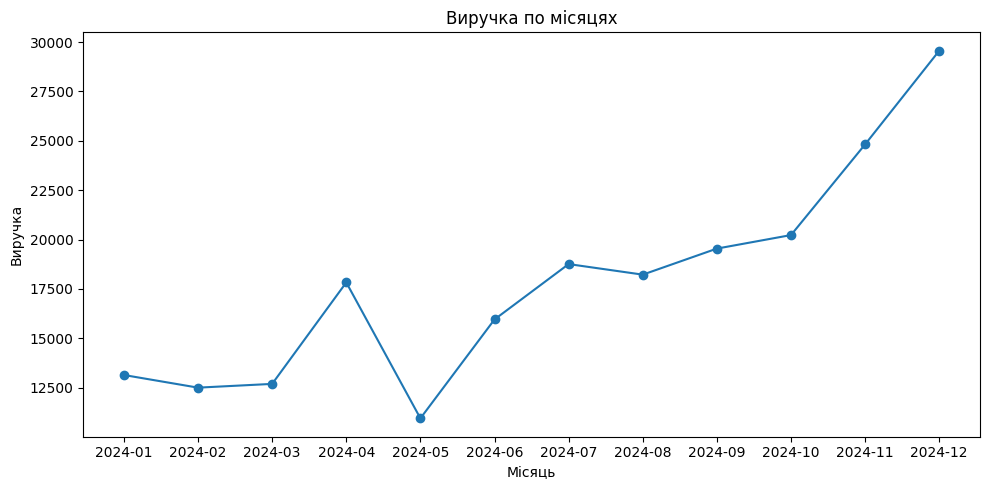

In [24]:
# Виручка по місяцях

plt.figure(figsize=(10, 5))
plt.plot(revenue_by_month.index.astype(str), revenue_by_month.values, marker="o")
plt.title("Виручка по місяцях")
plt.xlabel("Місяць")
plt.ylabel("Виручка")
plt.tight_layout()
plt.show()

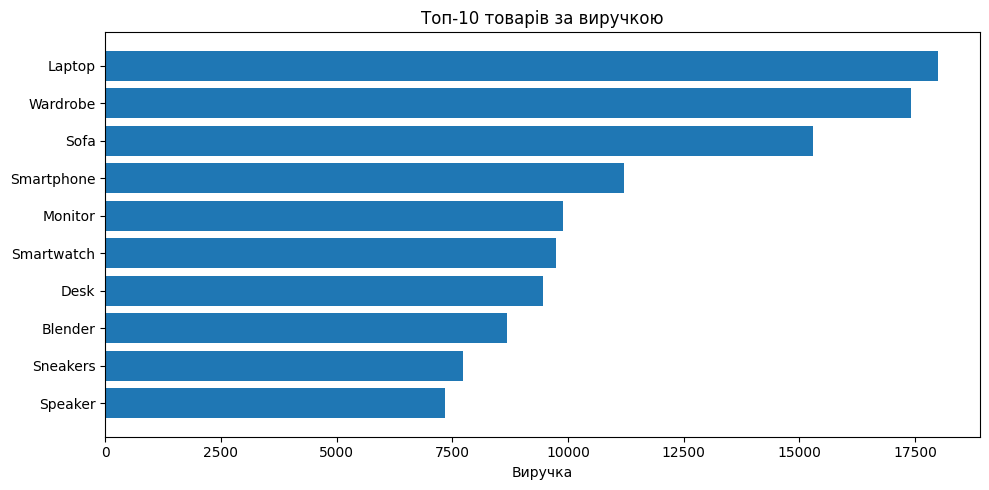

In [25]:
# Топ-10 товарів за виручкою

top10 = df.groupby("product")["revenue"].sum().nlargest(10).sort_values()

plt.figure(figsize=(10, 5))
plt.barh(top10.index, top10.values)
plt.title("Топ-10 товарів за виручкою")
plt.xlabel("Виручка")
plt.tight_layout()
plt.show()

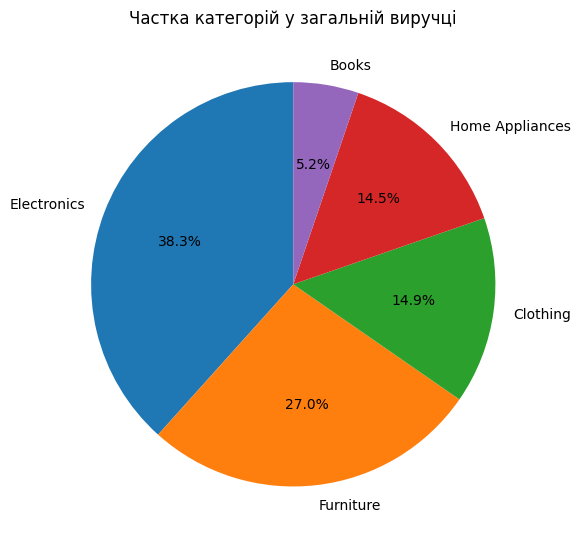

In [26]:
# Частка категорій у загальній виручці

plt.figure(figsize=(6, 6))
plt.pie(revenue_by_category.values, labels=revenue_by_category.index,autopct="%1.1f%%", startangle=90)
plt.title("Частка категорій у загальній виручці")
plt.tight_layout()
plt.show()